<a href="https://colab.research.google.com/github/Riyendo/VIT_architecture/blob/main/Finalized_UNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# !pip install ___

In [ ]:
# Import necessary libraries
import os, math, random # Standard libraries for file operations, math, and randomness
from pathlib import Path # For working with file paths in an object-oriented way
import numpy as np # For numerical operations, especially array manipulation
import cv2 # OpenCV library for image processing (reading, writing, manipulating images)
import matplotlib.pyplot as plt # For plotting and visualizing images
from tqdm.auto import tqdm # For displaying progress bars during loops

import torch # PyTorch library for building and training neural networks
import torch.nn as nn # Neural network modules (layers, loss functions, etc.)
import torch.nn.functional as F # Functional interface for common operations (e.g., activation functions)
from torch.utils.data import Dataset, DataLoader, random_split # Utilities for handling datasets and creating data loaders

import albumentations as A # Library for image augmentation (transformations to training data)
from albumentations.pytorch import ToTensorV2 # A specific transform to convert images to PyTorch tensors

from PIL import Image # Pillow library for image manipulation (used by OxfordIIITPet dataset)
from torchvision.datasets import OxfordIIITPet # Oxford-IIIT Pet dataset from torchvision

In [ ]:
# -------------------------
# 1) Download Oxford-IIIT Pet with segmentation trimaps
# -------------------------
# Define the root directory to store the dataset
ROOT = Path("/content/data")
# Create the directory if it doesn't exist
ROOT.mkdir(parents=True, exist_ok=True)

# Download the Oxford-IIIT Pet dataset with segmentation trimaps
# target_types='segmentation' returns the trimap masks with values in {1,2,3}
full_ds = OxfordIIITPet(root=str(ROOT), split="trainval", target_types="segmentation", download=True)
test_ds_raw = OxfordIIITPet(root=str(ROOT), split="test", target_types="segmentation", download=True)

# We will create our own Dataset wrapper to:
# - apply Albumentations transforms
# - convert trimap to binary mask: foreground = {2,3}, background = {1}
IMG_SIZE = 384 # Define the target image size for processing

# Define data transformations for the training set using Albumentations
train_tfms = A.Compose([
    A.LongestMaxSize(max_size=IMG_SIZE), # Resize the longest side to IMG_SIZE, maintaining aspect ratio
    A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT, value=0), # Pad the image to a square of IMG_SIZE
    A.HorizontalFlip(p=0.5), # Randomly flip the image horizontally with a probability of 0.5
    A.VerticalFlip(p=0.2), # Randomly flip the image vertically with a probability of 0.2
    A.RandomRotate90(p=0.2), # Randomly rotate the image by 90 degrees with a probability of 0.2
    A.ColorJitter(p=0.2, brightness=0.2, contrast=0.1, saturation=0.05), # Apply random color jittering
    A.GaussianBlur(p=0.1, blur_limit=(3,5)), # Apply random Gaussian blur
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), # Normalize pixel values using standard ImageNet means and stds
    ToTensorV2(), # Convert the image and mask to PyTorch tensors
])

# Define data transformations for the evaluation and test sets
eval_tfms = A.Compose([
    A.LongestMaxSize(max_size=IMG_SIZE), # Resize the longest side to IMG_SIZE, maintaining aspect ratio
    A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT, value=0), # Pad the image to a square of IMG_SIZE
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), # Normalize pixel values
    ToTensorV2(), # Convert to PyTorch tensors
])

# Custom Dataset class to wrap the base dataset and apply transformations
class PetSegDataset(Dataset):
    def __init__(self, base_ds, tfms):
        self.base = base_ds # Store the base dataset
        self.tfms = tfms # Store the transformations to apply

    def __len__(self):
        return len(self.base) # Return the number of samples in the dataset

    def __getitem__(self, idx):
        img_pil, mask_pil = self.base[idx]  # Get image and mask (PIL Image, PIL Image with trimap values 1,2,3)
        img = np.array(img_pil.convert("RGB")) # Convert image to numpy array (RGB format)
        mask = np.array(mask_pil)  # Convert mask to numpy array (values in {1,2,3})

        # Create a binary mask: treat {2,3} as foreground (value 1), background {1} as 0
        mask_bin = ((mask > 1).astype(np.uint8)) * 255 # Convert boolean mask to uint8 (0 or 1), then scale to 0 or 255

        # Apply the defined transformations to the image and binary mask
        out = self.tfms(image=img, mask=mask_bin)
        img_t = out["image"]                 # Get the transformed image tensor (float tensor, normalized)
        # Get the transformed mask tensor, convert to float, add a channel dimension, and scale to {0,1}
        mask_t = out["mask"].float().unsqueeze(0) / 255.0  # [1,H,W] in {0,1}
        return img_t, mask_t # Return the transformed image and mask tensors

# Split the full dataset (trainval) into training and validation sets
generator = torch.Generator().manual_seed(42) # Use a fixed seed for reproducibility
train_len = int(0.9 * len(full_ds)) # 90% for training
val_len = len(full_ds) - train_len # Remaining 10% for validation
train_raw, val_raw = random_split(full_ds, [train_len, val_len], generator=generator) # Perform the split

# Create instances of our custom dataset for train, validation, and test sets
train_ds = PetSegDataset(train_raw, train_tfms) # Training dataset with training transformations
val_ds   = PetSegDataset(val_raw,   eval_tfms) # Validation dataset with evaluation transformations
test_ds  = PetSegDataset(test_ds_raw, eval_tfms) # Test dataset with evaluation transformations

# Create DataLoaders for efficient batching and loading of data
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2, pin_memory=True) # DataLoader for training
val_loader   = DataLoader(val_ds,   batch_size=6, shuffle=False, num_workers=2, pin_memory=True) # DataLoader for validation

100%|██████████| 792M/792M [00:26<00:00, 29.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 16.2MB/s]
/tmp/ipython-input-674989374.py:22: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT, value=0), # Pad the image to a square of IMG_SIZE
/tmp/ipython-input-674989374.py:35: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT, value=0), # Pad the image to a square of IMG_SIZE


In [ ]:
# -------------------------
# 2) U-Net model
# -------------------------
# Define a Double Convolution block used in the U-Net
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        # Sequential container for two convolutional layers with Batch Normalization and ReLU activation
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), # First convolutional layer
            nn.BatchNorm2d(out_ch), # Batch normalization
            nn.ReLU(inplace=True), # ReLU activation
            nn.Conv2d(out_ch, out_ch, 3, padding=1), # Second convolutional layer
            nn.BatchNorm2d(out_ch), # Batch normalization
            nn.ReLU(inplace=True), # ReLU activation
        )
    def forward(self, x): return self.net(x) # Forward pass through the sequential layers

# Define a Downsampling block for the encoder part of U-Net
class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        # Sequential container for Max Pooling and a Double Convolution block
        self.net = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch)) # Max pooling reduces spatial dimensions
    def forward(self, x): return self.net(x) # Forward pass

# Define an Upsampling block for the decoder part of U-Net
class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        # Transposed convolution (upsampling)
        self.up = nn.ConvTranspose2d(in_ch, in_ch//2, kernel_size=2, stride=2)
        # Double Convolution block after upsampling and concatenation
        self.conv = DoubleConv(in_ch, out_ch)
    def forward(self, x1, x2):
        # x1 is the input from the previous upsampling layer
        # x2 is the skip connection from the corresponding encoder layer
        x1 = self.up(x1)
        # pad to handle odd sizes
        diffY = x2.size(2) - x1.size(2)
        diffX = x2.size(3) - x1.size(3)
        x1 = F.pad(x1, [diffX//2, diffX - diffX//2,
                        diffY//2, diffY - diffY//2]) # Pad x1 to match the spatial dimensions of x2
        x = torch.cat([x2, x1], dim=1) # Concatenate x2 and the padded x1 along the channel dimension
        return self.conv(x) # Forward pass through the Double Convolution block

# Define the U-Net model
class UNet(nn.Module):
    def __init__(self, in_ch=3, base=64):
        super().__init__()
        # Encoder part (downsampling path)
        self.inc = DoubleConv(in_ch, base) # Initial input convolution
        self.down1 = Down(base, base*2) # First downsampling block
        self.down2 = Down(base*2, base*4) # Second downsampling block
        self.down3 = Down(base*4, base*8) # Third downsampling block
        self.down4 = Down(base*8, base*16) # Fourth downsampling block (bottleneck)
        # Decoder part (upsampling path)
        self.up1 = Up(base*16, base*8) # First upsampling block
        self.up2 = Up(base*8, base*4) # Second upsampling block
        self.up3 = Up(base*4, base*2) # Third upsampling block
        self.up4 = Up(base*2, base) # Fourth upsampling block
        # Output layer (1x1 convolution to get the final segmentation mask)
        self.outc = nn.Conv2d(base, 1, kernel_size=1)
    def forward(self, x):
        # Forward pass through the U-Net
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4) # Upsample and concatenate with skip connection
        x = self.up2(x,  x3) # Upsample and concatenate with skip connection
        x = self.up3(x,  x2) # Upsample and concatenate with skip connection
        x = self.up4(x,  x1) # Upsample and concatenate with skip connection
        return self.outc(x) # Final output convolution

# Determine the device to use (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Create an instance of the UNet model and move it to the selected device
model = UNet().to(device)

In [ ]:
# -------------------------
# 3) Loss, metrics, optimiser
# -------------------------
# Define the Dice Loss function
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps # Small epsilon value to prevent division by zero
    def forward(self, logits, targets):
        # Apply sigmoid to the model's output logits to get probabilities
        probs = torch.sigmoid(logits)
        # Calculate the numerator of the Dice score (2 * intersection)
        num = 2 * (probs*targets).sum(dim=(2,3)) + self.eps
        # Calculate the denominator of the Dice score (sum of areas)
        den = (probs*probs).sum(dim=(2,3)) + (targets*targets).sum(dim=(2,3)) + self.eps
        # Return the average Dice Loss (1 - Dice Score) over the batch
        return (1 - num/den).mean()

# Define the Binary Cross-Entropy with Logits loss
bce = nn.BCEWithLogitsLoss()
# Create an instance of the Dice Loss
dice = DiceLoss()

# Define a combined loss function
def loss_fn(outputs, targets, alpha=0.5):
    # Combine BCE and Dice Loss with a weighting factor alpha
    return alpha*bce(outputs, targets) + (1-alpha)*dice(outputs, targets)

# Define the Intersection over Union (IoU) score metric
def iou_score(outputs, targets, thr=0.5):
    # Apply sigmoid to get probabilities
    probs = torch.sigmoid(outputs)
    # Threshold probabilities to get binary predictions
    preds = (probs > thr).float()
    # Calculate the intersection between predictions and ground truth
    inter = (preds*targets).sum(dim=(2,3))
    # Calculate the union between predictions and ground truth
    union = (preds + targets - preds*targets).sum(dim=(2,3)) + 1e-6 # Add epsilon to avoid division by zero
    # Return the average IoU score over the batch
    return (inter/union).mean().item()

# Define the optimizer (AdamW) for updating model parameters
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
# Define the learning rate scheduler (Cosine Annealing)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10) # T_max is the number of epochs for the cosine cycle

In [ ]:
# -------------------------
# 4) Training loop
# -------------------------
EPOCHS = 2  # Number of training epochs (adjust upward for potentially better results)

best_val_iou = 0.0 # Initialize the best validation IoU score
ckpt_path = "/content/unet_oxfordpet.pth" # Path to save the best model checkpoint

# Loop over the specified number of epochs
for epoch in range(1, EPOCHS+1):
    model.train() # Set the model to training mode
    train_loss = 0.0 # Initialize training loss for the epoch
    # Create a progress bar for the training data loader
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [train]")
    # Iterate over batches in the training data loader
    for imgs, masks in pbar:
        # Move images and masks to the device (GPU or CPU)
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad() # Zero the gradients of model parameters
        logits = model(imgs) # Perform a forward pass to get model outputs (logits)
        loss = loss_fn(logits, masks) # Calculate the loss
        loss.backward() # Perform backpropagation to calculate gradients
        optimizer.step() # Update model parameters using the optimizer
        train_loss += loss.item() * imgs.size(0) # Accumulate training loss
        pbar.set_postfix(loss=float(loss)) # Update the progress bar with the current loss

    model.eval() # Set the model to evaluation mode
    val_loss = 0.0 # Initialize validation loss for the epoch
    val_iou  = 0.0 # Initialize validation IoU for the epoch
    with torch.no_grad(): # Disable gradient calculation for evaluation
        # Iterate over batches in the validation data loader
        for imgs, masks in val_loader:
            # Move images and masks to the device
            imgs = imgs.to(device)
            masks = masks.to(device)
            logits = model(imgs) # Perform a forward pass
            loss = loss_fn(logits, masks) # Calculate the loss
            val_loss += loss.item() * imgs.size(0) # Accumulate validation loss
            val_iou  += iou_score(logits, masks) * imgs.size(0) # Accumulate validation IoU

    # Calculate average training and validation loss and IoU for the epoch
    train_loss /= len(train_loader.dataset)
    val_loss   /= len(val_loader.dataset)
    val_iou    /= len(val_loader.dataset)

    scheduler.step() # Step the learning rate scheduler

    # Print epoch summary
    print(f"Epoch {epoch}: train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_iou={val_iou:.4f}")

    # Save the model checkpoint if the current validation IoU is the best so far
    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), ckpt_path) # Save the model's state dictionary
        print(f"Saved best model with IoU={best_val_iou:.4f} -> {ckpt_path}")

Epoch 1/2 [train]:   0%|          | 0/414 [00:00<?, ?it/s]

/tmp/ipython-input-851839247.py:26: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  pbar.set_postfix(loss=float(loss)) # Update the progress bar with the current loss


Epoch 1: train_loss=0.2840  val_loss=0.3583  val_iou=0.6029
Saved best model with IoU=0.6029 -> /content/unet_oxfordpet.pth


Epoch 2/2 [train]:   0%|          | 0/414 [00:00<?, ?it/s]

Epoch 2: train_loss=0.2514  val_loss=0.6679  val_iou=0.3969


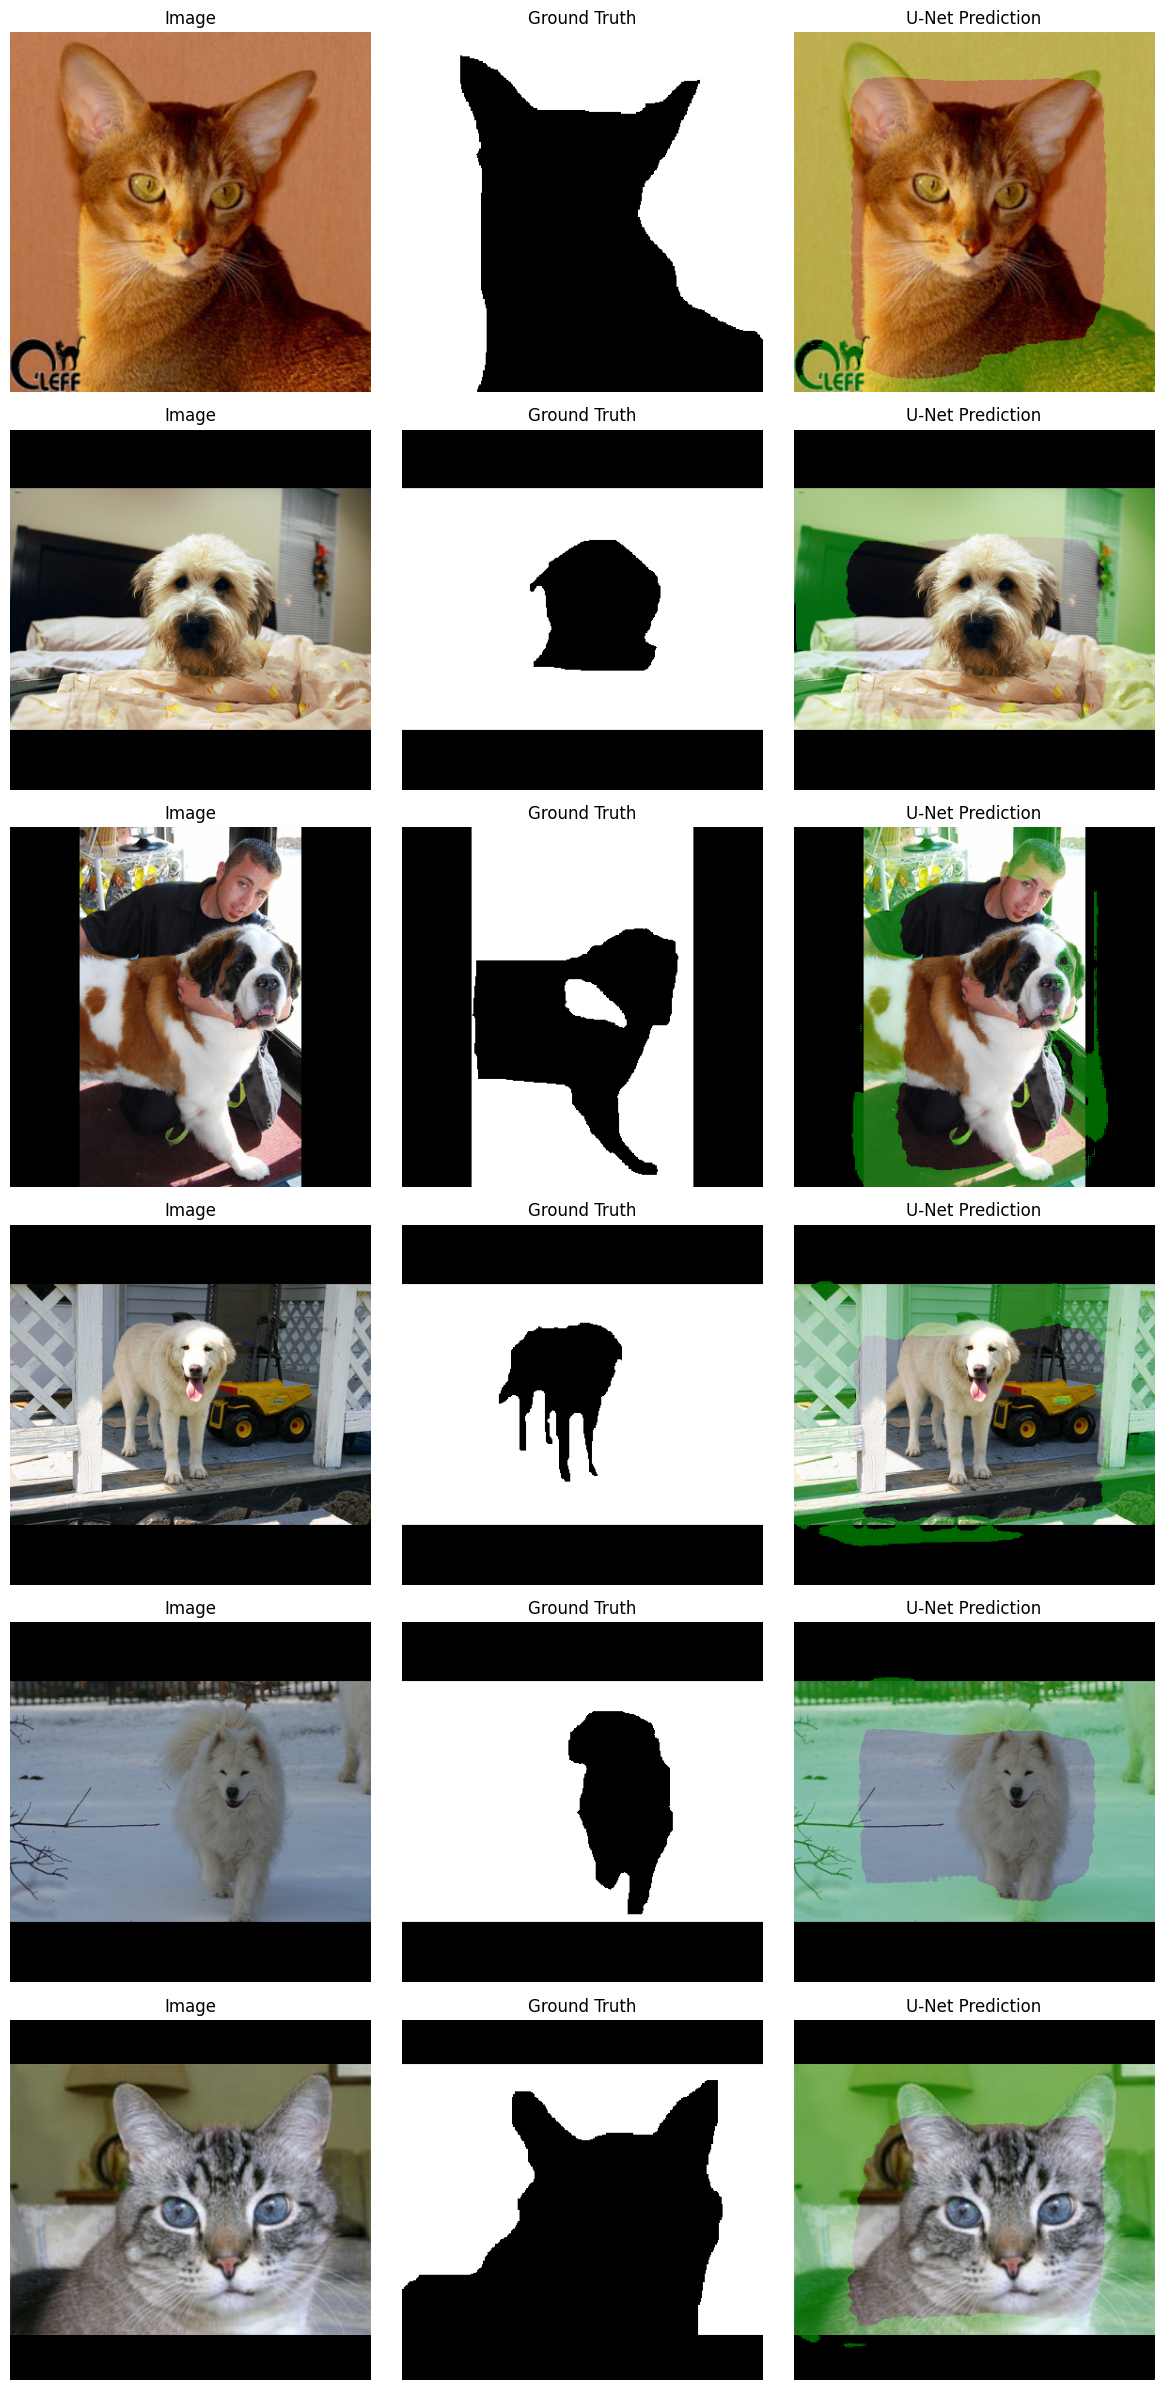

In [ ]:
# -------------------------
# 5) Visualise predictions on a few validation images
# -------------------------
# Load the state dictionary of the best performing model from the checkpoint
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval() # Set the model to evaluation mode

# Function to denormalize an image tensor
def denorm(img_t):
    # Invert the normalization used above
    # Convert tensor to numpy array and change dimension order from (C, H, W) to (H, W, C)
    img = img_t.numpy().transpose(1,2,0)
    # Apply inverse normalization using the mean and standard deviation used for normalization
    img = (img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])).clip(0,1) # Clip values to be within [0, 1]
    return img # Return the denormalized image (numpy array)

# Function to display sample images, ground truth masks, and model predictions
def show_samples(dataset, n=6, thr=0.5):
    # Randomly select n indices from the dataset
    idxs = np.random.choice(len(dataset), size=min(n, len(dataset)), replace=False)
    cols = 3 # Number of columns in the plot (Image, Ground Truth, Prediction)
    rows = int(np.ceil(len(idxs))) # Number of rows in the plot (number of samples)
    plt.figure(figsize=(cols*4, rows*4)) # Set the figure size
    i = 1 # Initialize subplot index
    # Iterate over the selected indices
    for idx in idxs:
        img_t, mask_t = dataset[idx] # Get image and mask tensors from the dataset
        img = denorm(img_t) # Denormalize the image for display
        with torch.no_grad(): # Disable gradient calculation
            # Add a batch dimension to the image tensor and move to device
            logits = model(img_t.unsqueeze(0).to(device))
            # Apply sigmoid to get probabilities, remove batch dimension, convert to numpy array
            prob = torch.sigmoid(logits)[0,0].cpu().numpy()
            # Threshold probabilities to get binary predictions (0 or 1)
            pred = (prob > thr).astype(np.float32)

        # Create an overlay for visualizing the prediction
        overlay = img.copy()
        # Boost the green channel where the model predicts foreground
        overlay[:,:,1] = np.maximum(overlay[:,:,1], pred)
        # Blend the original image with the overlay
        blended = (0.6*img + 0.4*overlay).clip(0,1)

        # Plot the original image
        plt.subplot(rows, cols, i); i+=1
        plt.imshow(img); plt.title("Image"); plt.axis("off")
        # Plot the ground truth mask
        plt.subplot(rows, cols, i); i+=1
        plt.imshow(mask_t.squeeze(0).numpy(), cmap="gray"); plt.title("Ground Truth"); plt.axis("off")
        # Plot the blended image with the prediction overlay
        plt.subplot(rows, cols, i); i+=1
        plt.imshow(blended); plt.title("U-Net Prediction"); plt.axis("off")
    plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
    plt.show() # Display the plot

# Show samples from the validation dataset
show_samples(val_ds, n=6, thr=0.5)